In [1]:
# Load the tools I need
import scanpy as sc
import pandas as pd

In [2]:
adata = sc.datasets.pbmc68k_reduced() 
adata

AnnData object with n_obs × n_vars = 700 × 765
    obs: 'bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain'
    var: 'n_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable'
    uns: 'bulk_labels_colors', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

In [3]:
adata.obs.head()

,bulk_labels,n_genes,percent_mito,n_counts,S_score,G2M_score,phase,louvain
index,,,,,,,,
AAAGCCTGGCTAAC-1,CD14+ Monocyte,1003,0.023856,2557.0,-0.119160,-0.816889,G1,1
AAATTCGATGCACA-1,Dendritic,1080,0.027458,2695.0,0.067026,-0.889498,S,1
AACACGTGGTCTTT-1,CD56+ NK,1228,0.016819,3389.0,-0.147977,-0.941749,G1,3
AAGTGCACGTGCTA-1,CD4+/CD25 T Reg,1007,0.011797,2204.0,0.065216,1.469291,G2M,9
ACACGAACGGAGTG-1,Dendritic,1178,0.017277,3878.0,-0.122974,-0.868185,G1,2


In [4]:
adata.obs["bulk_labels"].value_counts()

bulk_labels
Dendritic                       240
CD14+ Monocyte                  129
CD19+ B                          95
CD4+/CD25 T Reg                  68
CD8+ Cytotoxic T                 54
CD8+/CD45RA+ Naive Cytotoxic     43
CD56+ NK                         31
CD4+/CD45RO+ Memory              19
CD34+                            13
CD4+/CD45RA+/CD25- Naive T        8
Name: count, dtype: int64

In [5]:
adata.obs[["n_genes", "n_counts", "percent_mito"]].describe()

,n_genes,n_counts,percent_mito
count,700.000000,700.000000,700.000000
mean,1185.801429,3506.441406,0.017246
std,194.056116,839.288452,0.004915
min,1001.000000,2141.000000,0.004842
25%,1051.000000,2933.750000,0.013700
50%,1129.500000,3333.500000,0.016706
75%,1250.000000,3819.250000,0.020341
max,2605.000000,9497.000000,0.040042


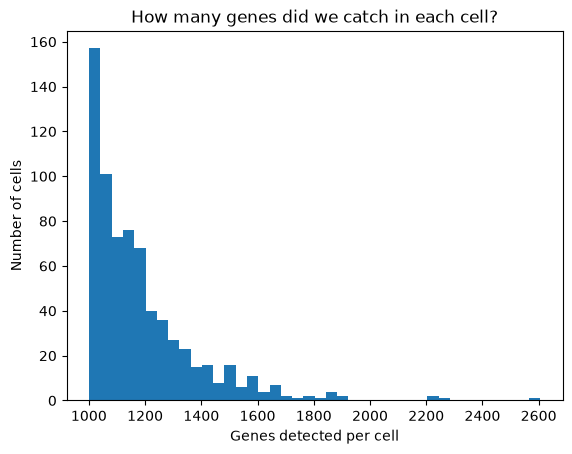

In [6]:
import matplotlib.pyplot as plt

plt.hist(adata.obs["n_genes"], bins=40)
plt.xlabel("Genes detected per cell")
plt.ylabel("Number of cells")
plt.title("How many genes did we catch in each cell?")
plt.show()

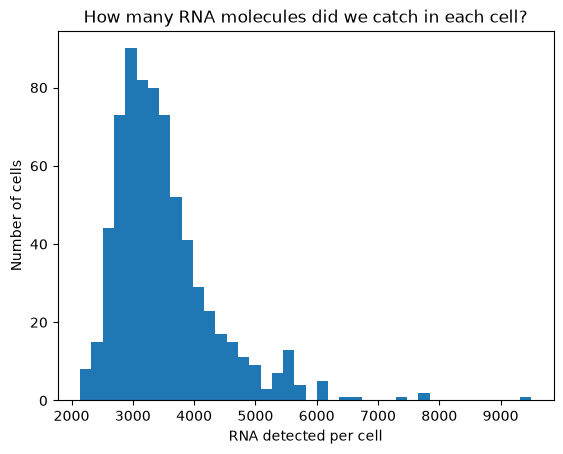

In [7]:
import matplotlib.pyplot as plt

plt.hist(adata.obs["n_counts"], bins=40)
plt.xlabel("RNA detected per cell")
plt.ylabel("Number of cells")
plt.title("How many RNA molecules did we catch in each cell?")
plt.show()

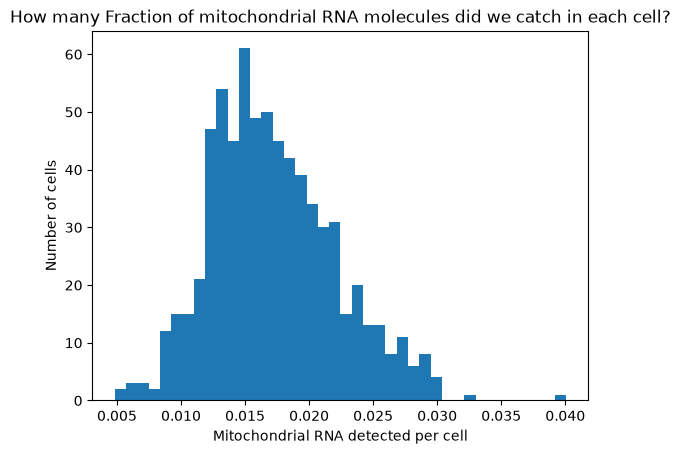

In [8]:
import matplotlib.pyplot as plt

plt.hist(adata.obs["percent_mito"], bins=40)
plt.xlabel("Mitochondrial RNA detected per cell")
plt.ylabel("Number of cells")
plt.title("How many Fraction of mitochondrial RNA molecules did we catch in each cell?")
plt.show()

## Do RNA counts and genes rise together?

A healthy cell with more RNA should also show more genes. Two things to look for:

- **Doublets** (two cells captured as one): unusually high counts *and* genes, far up and to the right.
- **Dying cells**: low counts with a high mitochondrial fraction (bright dots in the bottom left).

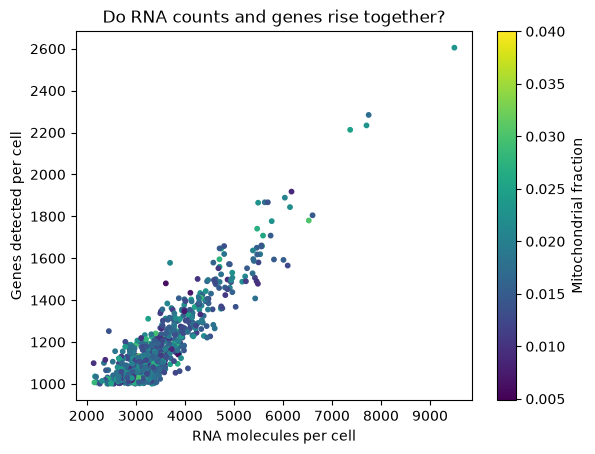

           n_genes  n_counts
n_genes   1.000000  0.914645
n_counts  0.914645  1.000000
Cells with more than 2,000 genes: 4


In [9]:
# One dot per cell: RNA counts (x) vs genes detected (y), colored by mitochondrial fraction
plt.scatter(adata.obs["n_counts"], adata.obs["n_genes"],
            c=adata.obs["percent_mito"], cmap="viridis", s=10)  # s = dot size
plt.colorbar(label="Mitochondrial fraction")  # legend for the colors
plt.xlabel("RNA molecules per cell")
plt.ylabel("Genes detected per cell")
plt.title("Do RNA counts and genes rise together?")
plt.show()

# Correlation: 1 = move together perfectly, 0 = unrelated
print(adata.obs[["n_genes", "n_counts"]].corr())

# How many cells sit in the high tail (possible doublets)?
print("Cells with more than 2,000 genes:", (adata.obs["n_genes"] > 2000).sum())

## QC conclusion

- RNA counts and genes detected rise together closely (correlation 0.91), as expected for healthy cells.
- No group of cells sits at low counts with high mitochondrial RNA, and the highest mitochondrial fraction is only 4%, so there is no sign of dying cells.
- Only 4 of 700 cells (0.6%) have more than 2,000 genes, the possible doublets. That is too few to change the results.

**Decision:** no cells removed. The dataset was already filtered (at least 1,000 genes per cell, under 5% mitochondrial RNA).